# Facial Image Preprocessing

In this notebook, I prepare the facial images collected from the group for the face-identification part of the assignment. I check the files, detect and crop faces, apply a few image transformations and extract HOG features for model training.

## Participant labels

- Ella: `participant_01`
- King: `participant_02`
- Nicole: `participant_03`
- Sarah: `participant_04`

The images should be placed in `data/images/raw/`. The folder names or filenames should make it clear which participant and expression each image belongs to. The notebook reports files with unclear labels instead of guessing their identity.

Example folder layout:

```text
data/images/raw/
  Ella/neutral/
  Ella/smiling/
  Ella/surprised/
  King/neutral/
  ...
```

## 1. Imports and project paths

I import the libraries used for reading images, processing them, displaying examples and extracting HOG features. The paths are set relative to the project so the notebook can be run from the project folder or the notebooks folder.

This environment uses Python 3.14 and the installed OpenCV 5 package. The face-detection step downloads the Haar cascade XML file into `data/models/` if it is missing. If another package is missing, it can be installed in the active virtual environment:

```powershell
python -m pip install --only-binary=:all: matplotlib pandas scikit-image tqdm
```

I avoid downgrading NumPy or installing the older OpenCV build because that caused package-installation problems in this environment.

In [9]:
import sys
from pathlib import Path
import re
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

print("Python version:", sys.version.split()[0])
print("Python executable:", sys.executable)
print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)

if sys.version_info[:2] != (3, 14):
    print("WARNING: This notebook is configured for Python 3.14.x. Select your Python 3.14.6 interpreter in VS Code.")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = ROOT / "data" / "images" / "raw"
PROCESSED_DIR = ROOT / "data" / "images" / "processed"
AUGMENTED_DIR = PROCESSED_DIR / "augmented"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
AUGMENTED_DIR.mkdir(parents=True, exist_ok=True)

PARTICIPANTS = {
    "ella": "participant_01", "participant_01": "participant_01",
    "king": "participant_02", "participant_02": "participant_02",
    "nicole": "participant_03", "participant_03": "participant_03",
    "sarah": "participant_04", "participant_04": "participant_04",
}
EXPRESSIONS = {"neutral", "smiling", "surprised"}
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

print("Project root:", ROOT)
print("Raw image folder:", RAW_DIR)
print("Raw folder exists:", RAW_DIR.exists())

Python version: 3.14.6
Python executable: c:\Users\a\Documents\formative_2_data_processing_personal\.venv\Scripts\python.exe
OpenCV version: 5.0.0
NumPy version: 2.5.1
Project root: c:\Users\a\Documents\formative_2_data_processing_personal
Raw image folder: c:\Users\a\Documents\formative_2_data_processing_personal\data\images\raw
Raw folder exists: True


## 2. Find the images and identify their labels

I search the image folders and filenames to identify the participant and facial expression. I review the resulting table to make sure the labels have been assigned correctly. Files that cannot be identified are listed separately and are not given guessed labels.

In [10]:
def tokens_from_path(path):
    rel = path.relative_to(RAW_DIR)
    return [part.lower() for part in rel.parts[:-1]] + [path.stem.lower()]

def identify_participant(path):
    tokens = tokens_from_path(path)
    joined = "_".join(tokens)
    for alias, label in PARTICIPANTS.items():
        if re.search(rf"(?<![a-z0-9]){re.escape(alias)}(?![a-z0-9])", joined):
            return label
    return None

def identify_expression(path):
    joined = "_".join(tokens_from_path(path))
    matches = [expr for expr in EXPRESSIONS
               if re.search(rf"(?<![a-z0-9]){expr}(?![a-z0-9])", joined)]
    return matches[0] if len(matches) == 1 else None

if not RAW_DIR.exists():
    raise FileNotFoundError(
        f"Image folder not found: {RAW_DIR}\n"
        "Download the shared Drive images and place them in data/images/raw/."
    )

image_paths = sorted(p for p in RAW_DIR.rglob("*")
                     if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
records, unresolved = [], []
for path in image_paths:
    participant = identify_participant(path)
    expression = identify_expression(path)
    if participant is None or expression is None:
        unresolved.append({"file": str(path.relative_to(RAW_DIR)),
                           "participant_detected": participant,
                           "expression_detected": expression})
    else:
        records.append({"path": path, "participant_id": participant,
                        "expression": expression})

inventory = pd.DataFrame(records)
print("Image files found:", len(image_paths))
print("Images with recognized labels:", len(inventory))
print("Unresolved files:", len(unresolved))
display(inventory.head(20))
if unresolved:
    display(pd.DataFrame(unresolved).head(30))

Image files found: 12
Images with recognized labels: 12
Unresolved files: 0


,path,participant_id,expression
0,c:\Users\a\Documents\formative_2_data_processi...,participant_01,neutral
1,c:\Users\a\Documents\formative_2_data_processi...,participant_01,smiling
2,c:\Users\a\Documents\formative_2_data_processi...,participant_01,surprised
3,c:\Users\a\Documents\formative_2_data_processi...,participant_02,neutral
4,c:\Users\a\Documents\formative_2_data_processi...,participant_02,smiling
5,c:\Users\a\Documents\formative_2_data_processi...,participant_02,surprised
6,c:\Users\a\Documents\formative_2_data_processi...,participant_03,neutral
7,c:\Users\a\Documents\formative_2_data_processi...,participant_03,smiling
8,c:\Users\a\Documents\formative_2_data_processi...,participant_03,surprised
9,c:\Users\a\Documents\formative_2_data_processi...,participant_04,neutral


## 3. Check image counts and quality

I check how many images are available for each participant and expression. The assignment asks for neutral, smiling and surprised expressions, so this table helps show whether all of those samples are present. I also check that the image files can be opened and have usable dimensions.

In [11]:
if inventory.empty:
    raise ValueError("No labeled images found. Check folder names and filenames.")

count_table = (inventory.groupby(["participant_id", "expression"])
               .size().unstack(fill_value=0)
               .reindex(columns=sorted(EXPRESSIONS), fill_value=0))
display(count_table)

quality = []
for row in inventory.itertuples():
    img = cv2.imread(str(row.path))
    if img is None:
        quality.append({"file": str(row.path), "readable": False,
                        "width": None, "height": None})
    else:
        h, w = img.shape[:2]
        quality.append({"file": str(row.path), "readable": True,
                        "width": w, "height": h})
quality_df = pd.DataFrame(quality)
display(quality_df.head(20))
print("Unreadable images:", int((~quality_df["readable"]).sum()))

expression,neutral,smiling,surprised
participant_id,,,
participant_01,1,1,1
participant_02,1,1,1
participant_03,1,1,1
participant_04,1,1,1


,file,readable,width,height
0,c:\Users\a\Documents\formative_2_data_processi...,True,960,1280
1,c:\Users\a\Documents\formative_2_data_processi...,True,960,1280
2,c:\Users\a\Documents\formative_2_data_processi...,True,960,1280
3,c:\Users\a\Documents\formative_2_data_processi...,True,390,412
4,c:\Users\a\Documents\formative_2_data_processi...,True,352,422
5,c:\Users\a\Documents\formative_2_data_processi...,True,358,372
6,c:\Users\a\Documents\formative_2_data_processi...,True,624,781
7,c:\Users\a\Documents\formative_2_data_processi...,True,563,669
8,c:\Users\a\Documents\formative_2_data_processi...,True,1121,1403
9,c:\Users\a\Documents\formative_2_data_processi...,True,343,328


Unreadable images: 0


## 4. Detect and standardise the face crops

I use a Haar cascade to locate faces in the images. The largest detected face is cropped, converted to grayscale and resized to 128 × 128 pixels. If the detector cannot find a face, I record that image as skipped rather than treating the full image as a face crop.

In [12]:
if not hasattr(cv2, "CascadeClassifier"):
    raise ImportError(
        f"cv2.CascadeClassifier is unavailable in OpenCV {cv2.__version__}. "
        "Check that the notebook is using the project's .venv interpreter."
    )

cascade_dir = ROOT / "data" / "models"
cascade_dir.mkdir(parents=True, exist_ok=True)
cascade_path = cascade_dir / "haarcascade_frontalface_default.xml"
cascade_url = (
    "https://raw.githubusercontent.com/opencv/opencv/4.x/"
    "data/haarcascades/haarcascade_frontalface_default.xml"
)

if not cascade_path.exists() or cascade_path.stat().st_size < 10000:
    print("Downloading the official OpenCV Haar face-detection model...")
    from urllib.request import Request, urlopen
    request = Request(cascade_url, headers={"User-Agent": "Mozilla/5.0"})
    try:
        with urlopen(request, timeout=45) as response:
            model_bytes = response.read()
        if len(model_bytes) < 10000 or b"opencv_storage" not in model_bytes:
            preview = model_bytes[:200].decode("utf-8", errors="replace")
            raise ValueError(
                "The downloaded response does not appear to be a Haar cascade XML. "
                f"Response begins: {preview!r}"
            )
        cascade_path.write_bytes(model_bytes)
    except Exception as exc:
        raise RuntimeError(
            "Could not download the Haar cascade XML. Check whether your network "
            f"allows access to {cascade_url}. Original error: {exc}"
        ) from exc

face_detector = cv2.CascadeClassifier(str(cascade_path))
if face_detector.empty():
    raise RuntimeError(f"OpenCV could not load the Haar cascade file: {cascade_path}")
print("Face detector loaded successfully:", cascade_path)

def extract_face(image_path, size=(128, 128)):
    image = cv2.imread(str(image_path))
    if image is None:
        return None
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    faces = face_detector.detectMultiScale(
        gray, scaleFactor=1.1, minNeighbors=5, minSize=(40, 40)
    )
    if len(faces) == 0:
        return None
    x, y, w, h = max(faces, key=lambda box: box[2] * box[3])
    margin = int(0.15 * max(w, h))
    x0, y0 = max(0, x-margin), max(0, y-margin)
    x1, y1 = min(gray.shape[1], x+w+margin), min(gray.shape[0], y+h+margin)
    crop = gray[y0:y1, x0:x1]
    return cv2.resize(crop, size, interpolation=cv2.INTER_AREA)

face_records, skipped = [], []
for row in tqdm(inventory.itertuples(), total=len(inventory)):
    face = extract_face(row.path)
    if face is None:
        skipped.append({"file": str(row.path), "reason": "Unreadable or no face detected"})
        continue
    face_records.append({
        "source_path": str(row.path),
        "participant_id": row.participant_id,
        "expression": row.expression,
        "face": face
    })

print("Successfully processed faces:", len(face_records))
print("Skipped images:", len(skipped))
if skipped:
    display(pd.DataFrame(skipped).head(30))

Face detector loaded successfully: c:\Users\a\Documents\formative_2_data_processing_personal\data\models\haarcascade_frontalface_default.xml


  0%|          | 0/12 [00:00<?, ?it/s]

Successfully processed faces: 11
Skipped images: 1


,file,reason
0,c:\Users\a\Documents\formative_2_data_processi...,Unreadable or no face detected


## 5. View the processed face crops

I display examples of the face crops to check whether the detection and resizing steps worked as expected. This is useful because the face detector can sometimes crop an image incorrectly, so the results should be checked visually.

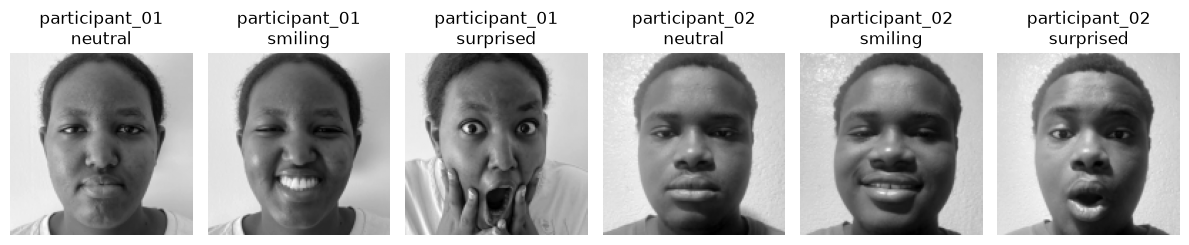

In [13]:
if face_records:
    fig, axes = plt.subplots(1, min(6, len(face_records)), figsize=(12, 3))
    axes = np.atleast_1d(axes)
    for ax, item in zip(axes, face_records[:6]):
        ax.imshow(item["face"], cmap="gray")
        ax.set_title(f'{item["participant_id"]}\n{item["expression"]}')
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    raise ValueError("No faces were detected. Review image quality and face orientation.")

## 6. Apply image augmentation

I create a few variations of each detected face using small rotations, horizontal flipping and contrast normalisation. These changes give the model slightly different versions of the same image.

The augmented images are still based on the original captures. They do not count as new people or new independent images. When splitting the data for training and testing, all variations from the same original image must stay in the same group.

In [14]:
def rotate_image(img, angle):
    h, w = img.shape
    matrix = cv2.getRotationMatrix2D((w/2, h/2), angle, 1.0)
    return cv2.warpAffine(img, matrix, (w, h),
                          flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REFLECT)

augmented_records = []
for idx, item in enumerate(tqdm(face_records)):
    base = item["face"]
    variants = [
        ("original", base),
        ("rotated_plus_10", rotate_image(base, 10)),
        ("rotated_minus_10", rotate_image(base, -10)),
        ("horizontal_flip", cv2.flip(base, 1)),
        ("contrast_normalized", cv2.equalizeHist(base)),
    ]
    for aug_name, image in variants:
        out_name = f'{item["participant_id"]}_{idx:04d}_{item["expression"]}_{aug_name}.png'
        out_path = AUGMENTED_DIR / out_name
        cv2.imwrite(str(out_path), image)
        augmented_records.append({
            "image_path": str(out_path),
            "source_path": item["source_path"],
            "participant_id": item["participant_id"],
            "expression": item["expression"],
            "augmentation": aug_name,
            "image": image
        })

augmented_df = pd.DataFrame([{k:v for k,v in x.items() if k != "image"}
                             for x in augmented_records])
print("Original detected faces:", len(face_records))
print("Augmented images including originals:", len(augmented_records))
display(augmented_df.head())

  0%|          | 0/11 [00:00<?, ?it/s]

Original detected faces: 11
Augmented images including originals: 55


,image_path,source_path,participant_id,expression,augmentation
0,c:\Users\a\Documents\formative_2_data_processi...,c:\Users\a\Documents\formative_2_data_processi...,participant_01,neutral,original
1,c:\Users\a\Documents\formative_2_data_processi...,c:\Users\a\Documents\formative_2_data_processi...,participant_01,neutral,rotated_plus_10
2,c:\Users\a\Documents\formative_2_data_processi...,c:\Users\a\Documents\formative_2_data_processi...,participant_01,neutral,rotated_minus_10
3,c:\Users\a\Documents\formative_2_data_processi...,c:\Users\a\Documents\formative_2_data_processi...,participant_01,neutral,horizontal_flip
4,c:\Users\a\Documents\formative_2_data_processi...,c:\Users\a\Documents\formative_2_data_processi...,participant_01,neutral,contrast_normalized


## 7. Extract HOG features

I use Histogram of Oriented Gradients (HOG) to describe the edge and shape patterns in each face crop. The resulting feature vectors can be used by the classifiers in the model-training notebook. HOG is a simple baseline feature method, so it should not be treated as a modern face-recognition embedding.

In [15]:
from skimage.feature import hog

feature_rows = []
for item in tqdm(augmented_records):
    image = item["image"]
    vector = hog(
        image,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        feature_vector=True
    )
    row = {
        "image_path": item["image_path"],
        "source_path": item["source_path"],
        "participant_id": item["participant_id"],
        "expression": item["expression"],
        "augmentation": item["augmentation"],
    }
    row.update({f"hog_{i:04d}": float(value)
                for i, value in enumerate(vector)})
    feature_rows.append(row)

image_features = pd.DataFrame(feature_rows)
print("Feature table shape:", image_features.shape)
display(image_features.iloc[:5, :12])

  0%|          | 0/55 [00:00<?, ?it/s]

Feature table shape: (55, 8105)


,image_path,source_path,participant_id,expression,augmentation,hog_0000,hog_0001,hog_0002,hog_0003,hog_0004,hog_0005,hog_0006
0,c:\Users\a\Documents\formative_2_data_processi...,c:\Users\a\Documents\formative_2_data_processi...,participant_01,neutral,original,0.261730,0.090134,0.076008,0.072534,0.228419,0.030045,0.190020
1,c:\Users\a\Documents\formative_2_data_processi...,c:\Users\a\Documents\formative_2_data_processi...,participant_01,neutral,rotated_plus_10,0.271381,0.149294,0.165238,0.037324,0.271381,0.000000,0.118027
2,c:\Users\a\Documents\formative_2_data_processi...,c:\Users\a\Documents\formative_2_data_processi...,participant_01,neutral,rotated_minus_10,0.269179,0.126825,0.240633,0.042275,0.269179,0.042275,0.053474
3,c:\Users\a\Documents\formative_2_data_processi...,c:\Users\a\Documents\formative_2_data_processi...,participant_01,neutral,horizontal_flip,0.264594,0.000000,0.000000,0.000000,0.264594,0.179131,0.264594
4,c:\Users\a\Documents\formative_2_data_processi...,c:\Users\a\Documents\formative_2_data_processi...,participant_01,neutral,contrast_normalized,0.261236,0.126578,0.066501,0.081130,0.261236,0.036135,0.235158


## 8. Save the features and processing details

I save the extracted features in `image_features.csv`. I also save an inventory of the images and a separate file for images that were skipped. This makes it easier to check which files were included in the final feature table.

In [16]:
image_features_path = PROCESSED_DIR / "image_features.csv"
inventory_path = PROCESSED_DIR / "image_inventory.csv"
skipped_path = PROCESSED_DIR / "skipped_images.csv"

image_features.to_csv(image_features_path, index=False)
inventory.drop(columns=["path"]).assign(
    path=inventory["path"].astype(str)
).to_csv(inventory_path, index=False)
pd.DataFrame(skipped).to_csv(skipped_path, index=False)

print("Saved:")
print(image_features_path)
print(inventory_path)
print(skipped_path)

Saved:
c:\Users\a\Documents\formative_2_data_processing_personal\data\images\processed\image_features.csv
c:\Users\a\Documents\formative_2_data_processing_personal\data\images\processed\image_inventory.csv
c:\Users\a\Documents\formative_2_data_processing_personal\data\images\processed\skipped_images.csv


## 9. Final checks and limitations

Before moving on, I check that the participant IDs and expression labels appear in the processed data and review any skipped images. The face dataset is small, so the results from a model trained on it will only be a basic demonstration.

It is important to split the data by the original image path. If augmented versions of one image appear in both the training and test sets, the evaluation can look better than it really is because the model has already seen very similar images.

The next notebook covers the voice recordings.